In [2]:
import copy
import math
import multiprocessing
import os
import random
import time
import warnings
from collections.abc import Callable
from functools import partial

from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torch.utils.flop_counter import FlopCounterMode

from dataset_loading import get_batch, prepare

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# mixed precision (float16) training on CUDA GPUs
USE_AMP = device.type == "cuda"

# channels-last memory layout speeds up convolutions on CUDA GPUs
MEMORY_FORMAT = (
    torch.channels_last if device.type == "cuda" else torch.contiguous_format
)

# pick the fastest convolution algorithms for our shapes
torch.backends.cudnn.benchmark = True

print(
    f"PyTorch {torch.__version__}, device: {device}"
)

PyTorch 2.14.1+cu130, device: cuda


## Training loop

In [ ]:
from train import evaluate, fit, generate

## Model decoder-only transformer (GPT-style)

In [ ]:
class CausalSelfAttentionSimpler(nn.Module):
    def __init__(self, d_model: int, n_heads: int):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads # 384 / 6 = 64
        self.wq = nn.Linear(d_model, d_model, bias=False)   # token -> query
        self.wk = nn.Linear(d_model, d_model, bias=False)   # token -> key
        self.wv = nn.Linear(d_model, d_model, bias=False)   # token -> value
        self.proj = nn.Linear(d_model, d_model, bias=False) # mixes the heads at the end

    def forward(self, x):
        B, T, C = x.shape
        H, hd = self.n_heads, self.head_dim

        q, k, v = self.wq(x), self.wk(x), self.wv(x) # each (B, T, C). Linear uses only last axis in multiplication.

        q = q.view(B, T, H, hd).transpose(1, 2) # (B, H, T, hd)
        k = k.view(B, T, H, hd).transpose(1, 2)
        v = v.view(B, T, H, hd).transpose(1, 2)

        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # (B, H, T, hd)

        y = y.transpose(1, 2).reshape(B, T, C) # (B, T, C)
        return self.proj(y)

In [ ]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)  # queries, keys, values in one matmul
        self.proj = nn.Linear(d_model, d_model, bias=False)  # mixes the heads back together

    def forward(self, x):
        # batch, sentence length, model dimensions
        B, T, C = x.shape
        # (B, T, 3C) -> (3, B, heads, T, head_dim)

        q, k, v = self.qkv(x).view(B, T, 3, self.n_heads, C // self.n_heads).permute(2, 0, 3, 1, 4)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

In [ ]:
class MLP(nn.Module):
    def __init__(self, d_model: int):
        super().__init__()
        self.fc = nn.Linear(d_model, 4 * d_model, bias=False)
        self.proj = nn.Linear(4 * d_model, d_model, bias=False)

    def forward(self, x):
        return self.proj(F.gelu(self.fc(x)))


class Block(nn.Module):
    """Pre-norm transformer block: normalize, transform, add back to the residual stream."""

    def __init__(self, d_model: int, n_heads: int):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d_model), CausalSelfAttentionSimpler(d_model, n_heads)
        self.ln2, self.mlp = nn.LayerNorm(d_model), MLP(d_model)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    def __init__(self, vocab_size: int, block_size: int, d_model: int, n_layers: int, n_heads: int):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)  # token id -> vector
        self.pos_emb = nn.Embedding(block_size, d_model)  # position -> vector (attention itself is order-blind)

        self.blocks = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_layers)])

        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)  # vector -> score for every token
        self.head.weight = self.tok_emb.weight  # weight tying: saves vocab_size * d_model parameters

        self.apply(self._init)
        # residual-branch outputs get a smaller init so the residual stream does not grow with depth
        for name, p in self.named_parameters():
            if name.endswith("proj.weight"):
                nn.init.normal_(p, std=0.02 / math.sqrt(2 * n_layers))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx):  # idx: (B, T) token ids -> logits (B, T, vocab_size)
        B, T = idx.shape
        assert T <= self.block_size, f"sequence length {T} > block_size {self.block_size}"
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))

## Build the model

In [ ]:
# --- config: shrink these if the GPU runs out of memory ---
BLOCK_SIZE, BATCH_SIZE = 256, 64
D_MODEL, N_LAYERS, N_HEADS = 384, 6, 6

tok = prepare()
model = GPT(tok.get_vocab_size(), BLOCK_SIZE, D_MODEL, N_LAYERS, N_HEADS).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

model.train()

17.0M parameters


## Train

In [7]:
import gc
gc.collect()
torch.cuda.empty_cache()

In [ ]:
history = fit(model, steps=5000, batch_size=BATCH_SIZE, block_size=BLOCK_SIZE)

training:   0%|          | 0/10 [00:00<?, ?it/s]

step     10/10 | train loss 9.530 | val loss 9.208 (ppl 9972.9) | 146 s


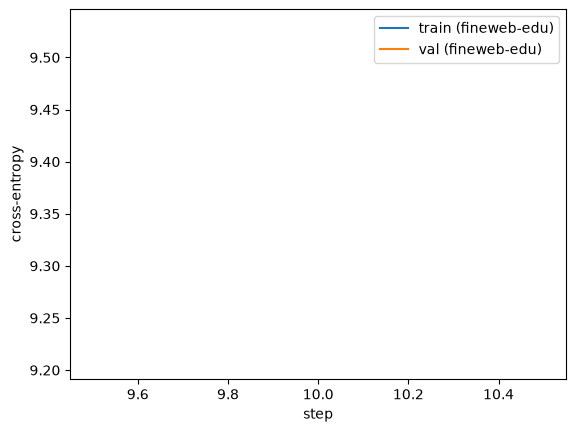

In [9]:
plt.plot(history["step"], history["train_loss"], label="train (fineweb-edu)")
plt.plot(history["step"], history["val_loss"], label="val (fineweb-edu)")
plt.xlabel("step"), plt.ylabel("cross-entropy"), plt.legend();

## Test on Wikipedia

In [10]:
test_loss = evaluate(model, "test", BLOCK_SIZE, BATCH_SIZE, n_batches=100)
print(f"wikipedia test loss {test_loss:.3f}, perplexity {math.exp(test_loss):.1f}")

wikipedia test loss 9.391, perplexity 11985.4


## Inference: prompt completions

In [ ]:
prompts = [
    "The capital of France is",
    "In 1969, the first humans",
    "Photosynthesis is the process by which",
    "The most important thing in a good education is",
    "To make a good cup of coffee, you should",
    "The history of the Roman Empire began",
    "Scientists have recently discovered that",
    "The main difference between a virus and a bacterium is",
    "When learning a new language, it helps to",
    "The president announced yesterday that",
]
for p in prompts:
    print(f"PROMPT: {p}\nOUTPUT: {generate(model, tok, p, max_new_tokens=60, block_size=BLOCK_SIZE)}\n")

## Inference time

In [ ]:
# inference speed: generate a fixed number of tokens (stop_at_eot=False so the length is exact)
N_NEW = 200
generate(model, tok, prompts[0], 10, block_size=BLOCK_SIZE, stop_at_eot=False)  # warm-up
if device.type == "cuda":
    torch.cuda.synchronize()

start = time.time()
generate(model, tok, prompts[0], N_NEW, block_size=BLOCK_SIZE, stop_at_eot=False)
if device.type == "cuda":
    torch.cuda.synchronize()
elapsed = time.time() - start

print(f"{N_NEW} tokens in {elapsed:.2f} s -> {N_NEW / elapsed:.1f} tokens/s")